In this notebook we will load in some data and plot it in several different ways.

In [1]:
# This is a fresh notebook so we need to import both packages again
import matplotlib.pyplot as plt # Making sure to use the common aliases for our packages
import pandas as pd

In [3]:
# The first step is to read in the data and check that it was read correctly
data = pd.read_csv("data/gapminder_gdp_oceania.csv", index_col = "country") # again we will set the index as the country
data.head()

,gdpPercap_1952,gdpPercap_1957,gdpPercap_1962,gdpPercap_1967,gdpPercap_1972,gdpPercap_1977,gdpPercap_1982,gdpPercap_1987,gdpPercap_1992,gdpPercap_1997,gdpPercap_2002,gdpPercap_2007
country,,,,,,,,,,,,
Australia,10039.59564,10949.64959,12217.22686,14526.12465,16788.62948,18334.19751,19477.00928,21888.88903,23424.76683,26997.93657,30687.75473,34435.36744
New Zealand,10556.57566,12247.39532,13175.67800,14463.91893,16046.03728,16233.71770,17632.41040,19007.19129,18363.32494,21050.41377,23189.80135,25185.00911


In [4]:
# chaining together attributes and methods
# note: this is a series of calls made in a single line, so let's break it down
# The dataframe, data, has an attribute columns
# columns is an array and the array has an attribute str (access the values as strings)
# strings have a method called replace and replace takes the first argument and replaces it with the second in a string
# So we have taken a dataframe and returned an array with an updated set of strings
# It has not changed the dataframe, but made a new variable with this array
years = data.columns.str.replace("gdpPercap_", "")
print(years)

Index(['1952', '1957', '1962', '1967', '1972', '1977', '1982', '1987', '1992',
       '1997', '2002', '2007'],
      dtype='object')


(1910.0, 2010.0)

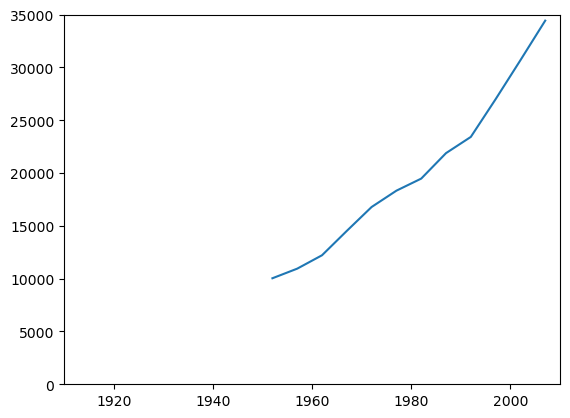

In [7]:
# We want the years as integers so that matplotlib can understand them to include in the ticks
# We can change the data type with the .astype() method and set the numbers as integers
# NOTE: this would not work if we still had country as one of the columns as it can't be changed to an integer
data.columns = years.astype(int)
# Dataframes use matplotlib to use their plot method
data.loc["Australia"].plot()
# Setting limit for the x and y axes
plt.ylim([0, 35000])
plt.xlim([1910, 2010])

Text(0, 0.5, 'GDP per capita')

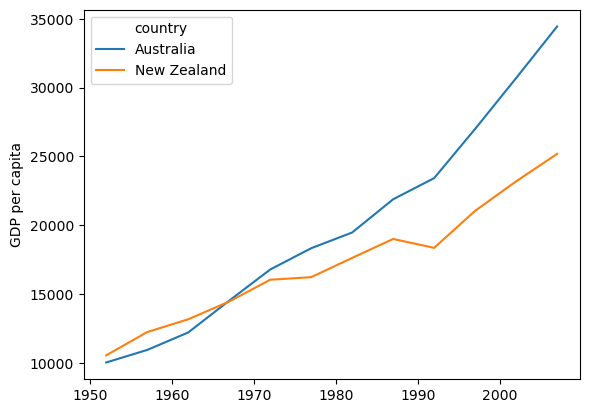

In [8]:
# This time we transpose the data (rotate by 90 degrees) and plot the whole dataframe
# This plot will take each column as its own dataset and label it with the column name (now the country names)
data.T.plot()
plt.ylabel("GDP per capita")

Text(0, 0.5, 'GDP per capita')

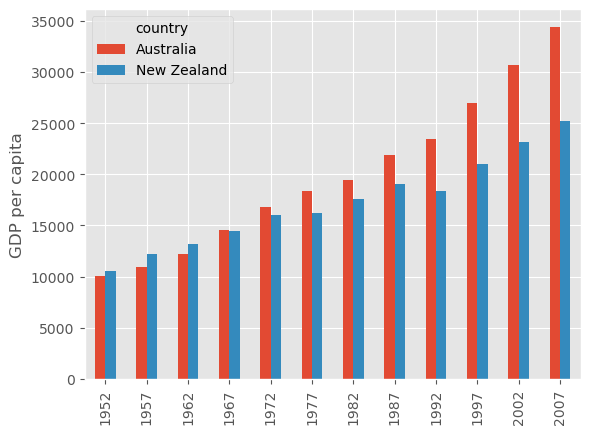

In [9]:
# matplotlib is very versatile and has some predetermined styles in built as well
# for those who are used to R or work in a field where R is common you might want your plots to look the same
# ggplot is the most popular R plotting library and matplotlib can replicate its style
plt.style.use("ggplot") # We provide a string and the method knows what to do with it
data.T.plot(kind = "bar") # We can make use of the kind argument in the plot method to change the chart type
plt.ylabel("GDP per capita") 

In [ ]:
# Example pseudo code of how you might plot the log of some data
# plt.plot(math.log(data["x"]), data["y"])

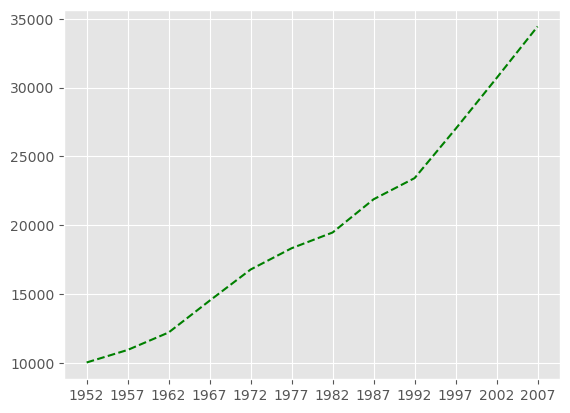

In [10]:
# There is also an argument in plot to provide the colour and styl in shorthand
gdp_australia = data.loc["Australia"]
plt.plot(years, gdp_australia, "g--") # green and dashed line

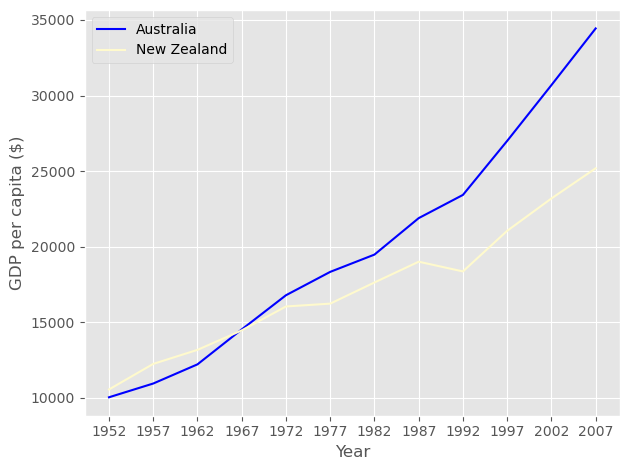

In [12]:
# Let's explicitly plot the two countries on the same figure
# making a separate dataframe for new zealand
gdp_nz = data.loc["New Zealand"]

# plotting both countries with unique styles
plt.plot(years, gdp_australia, "b-", label = "Australia")
plt.plot(years, gdp_nz, color = "lemonchiffon", label = "New Zealand")
# If you want to know more colour names in matplotlib check them out:
# https://matplotlib.org/stable/gallery/color/named_colors.html
# You can also choose colour with RGBA and hex codes: 
# https://matplotlib.org/stable/users/explain/colors/colors.html 

# adding a legend and axes labels
plt.legend(loc = "upper left")
plt.xlabel("Year")
plt.ylabel("GDP per capita ($)")
plt.tight_layout()